# 10 — Analysis of field presence/absence results

## Purpose

Notebook 09 completed the full methodological pipeline of the paper on the recovered field recordings.
This notebook **does not change the detector**. It only analyzes the outputs already produced.

The objective is to answer:

1. How often is each modelled species detected as present?
2. How many accepted detections are produced per species?
3. How do results vary by pond and month when those metadata are available?
4. Which species dominate the detector output?
5. Are there obvious field-domain behaviors that should be documented as limitations?
6. How does our replication compare **methodologically** with the paper?

### Important interpretation rule

The recovered field recordings are not required to contain the same number of samples as the article.
The goal of this project is to reproduce the **methodology**, using the data available locally.

Therefore differences such as `546` recovered field WAVs versus the paper's `141` samples are recorded
as dataset differences, **not as replication failures**.

No thresholds, segmentation constants, features or GMMs are changed here.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 200)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

FIELD_DIR = (
    REPO_ROOT
    / "data"
    / "processed"
    / "field_presence_absence"
)

PRESENCE_PATH = FIELD_DIR / "field_presence_absence.csv"
RUN_LOG_PATH = FIELD_DIR / "field_run_log.csv"
DETECTIONS_PATH = FIELD_DIR / "field_detector_decisions.csv"
DEDUP_PATH = FIELD_DIR / "field_accepted_detections_deduplicated.csv"
INVENTORY_PATH = FIELD_DIR / "field_inventory.csv"
MANIFEST_PATH = FIELD_DIR / "field_inference_manifest.json"

required = [
    PRESENCE_PATH,
    RUN_LOG_PATH,
    DETECTIONS_PATH,
    INVENTORY_PATH,
    MANIFEST_PATH,
]

for path in required:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing notebook-09 output: {path}"
        )

print("Field results directory:", FIELD_DIR)

Field results directory: C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\field_presence_absence


## 2. Load notebook-09 outputs

In [2]:
field_presence = pd.read_csv(
    PRESENCE_PATH
)

field_run_log = pd.read_csv(
    RUN_LOG_PATH
)

field_detections = pd.read_csv(
    DETECTIONS_PATH
)

field_inventory = pd.read_csv(
    INVENTORY_PATH
)

field_accepted_deduplicated = (
    pd.read_csv(
        DEDUP_PATH
    )
    if DEDUP_PATH.exists()
    else pd.DataFrame()
)

with open(
    MANIFEST_PATH,
    "r",
    encoding="utf-8",
) as f:
    field_manifest = json.load(f)

print("Presence rows           :", len(field_presence))
print("Run-log rows            :", len(field_run_log))
print("Detector-decision rows  :", len(field_detections))
print("Deduplicated accepted   :", len(field_accepted_deduplicated))
print("Inventory rows          :", len(field_inventory))

Presence rows           : 546
Run-log rows            : 546
Detector-decision rows  : 1376119
Deduplicated accepted   : 231058
Inventory rows          : 1680


## 3. Execution integrity

Before interpreting biology, verify that the computational run itself completed as intended.

In [3]:
successful = (
    field_run_log["status"]
    .astype(str)
    .eq("ok")
)

run_integrity = pd.DataFrame([
    {
        "metric": "files_in_run_log",
        "value": len(field_run_log),
    },
    {
        "metric": "successful_files",
        "value": int(successful.sum()),
    },
    {
        "metric": "failed_files",
        "value": int((~successful).sum()),
    },
    {
        "metric": "presence_rows",
        "value": len(field_presence),
    },
    {
        "metric": "detector_decisions",
        "value": len(field_detections),
    },
    {
        "metric": "deduplicated_accepted",
        "value": len(field_accepted_deduplicated),
    },
])

display(run_integrity)

if (~successful).any():
    display(
        field_run_log.loc[
            ~successful,
            [
                "sample_id",
                "error",
            ],
        ].head(30)
    )

,metric,value
0,files_in_run_log,546
1,successful_files,546
2,failed_files,0
3,presence_rows,546
4,detector_decisions,1376119
5,deduplicated_accepted,231058


## 4. Species names and model status

In [4]:
SPECIES = {
    "f01": "Boana alfaroi",
    "f02": "Dendropsophus bifurcus",
    "f03": "Boana cinerascens",
    "f04": "Pristimantis conspicillatus",
    "f05": "Leptodactylus discodactylus",
    "f06": "Osteocephalus fuscifacies",
    "f07": "Boana lanciformis",
    "f08": "Rhinella margaritifera",
    "f09": "Dendropsophus parviceps",
    "f10": "Engystomops petersi",
}

PAPER_ORDER = tuple(
    SPECIES.keys()
)

MODELLED_CODES = tuple(
    field_manifest[
        "classes_modelled"
    ]
)

species_status = pd.DataFrame([
    {
        "code": code_name,
        "species": SPECIES[code_name],
        "modelled": code_name in MODELLED_CODES,
    }
    for code_name in PAPER_ORDER
])

display(species_status)

,code,species,modelled
0,f01,Boana alfaroi,True
1,f02,Dendropsophus bifurcus,True
2,f03,Boana cinerascens,True
3,f04,Pristimantis conspicillatus,True
4,f05,Leptodactylus discodactylus,True
5,f06,Osteocephalus fuscifacies,True
6,f07,Boana lanciformis,True
7,f08,Rhinella margaritifera,True
8,f09,Dendropsophus parviceps,False
9,f10,Engystomops petersi,True


## 5. Presence/absence summary

For every modelled species:

- `presence = 1` means at least one call was accepted somewhere in that field WAV;
- `presence = 0` means no accepted detection was produced;
- `f09 = NA` because no deployable model could be trained from the recovered labelled material.

These are **detector outputs**, not independently verified ecological ground truth.

In [5]:
presence_rows = []

for code_name in PAPER_ORDER:
    column = f"presence_{code_name}"

    if code_name not in MODELLED_CODES:
        presence_rows.append({
            "code": code_name,
            "species": SPECIES[code_name],
            "modelled": False,
            "n_samples": len(field_presence),
            "n_present": np.nan,
            "n_absent": np.nan,
            "presence_fraction": np.nan,
        })
        continue

    values = pd.to_numeric(
        field_presence[column],
        errors="coerce",
    )

    presence_rows.append({
        "code": code_name,
        "species": SPECIES[code_name],
        "modelled": True,
        "n_samples": int(values.notna().sum()),
        "n_present": int((values == 1).sum()),
        "n_absent": int((values == 0).sum()),
        "presence_fraction": float(values.mean()),
    })

presence_summary = pd.DataFrame(
    presence_rows
)

display(
    presence_summary.round(4)
)

presence_summary.to_csv(
    FIELD_DIR / "analysis_presence_summary.csv",
    index=False,
)

,code,species,modelled,n_samples,n_present,n_absent,presence_fraction
0,f01,Boana alfaroi,True,546,37.0,509.0,0.0678
1,f02,Dendropsophus bifurcus,True,546,456.0,90.0,0.8352
2,f03,Boana cinerascens,True,546,229.0,317.0,0.4194
3,f04,Pristimantis conspicillatus,True,546,163.0,383.0,0.2985
4,f05,Leptodactylus discodactylus,True,546,130.0,416.0,0.2381
5,f06,Osteocephalus fuscifacies,True,546,259.0,287.0,0.4744
6,f07,Boana lanciformis,True,546,119.0,427.0,0.2179
7,f08,Rhinella margaritifera,True,546,80.0,466.0,0.1465
8,f09,Dendropsophus parviceps,False,546,NaN,NaN,NaN
9,f10,Engystomops petersi,True,546,62.0,484.0,0.1136


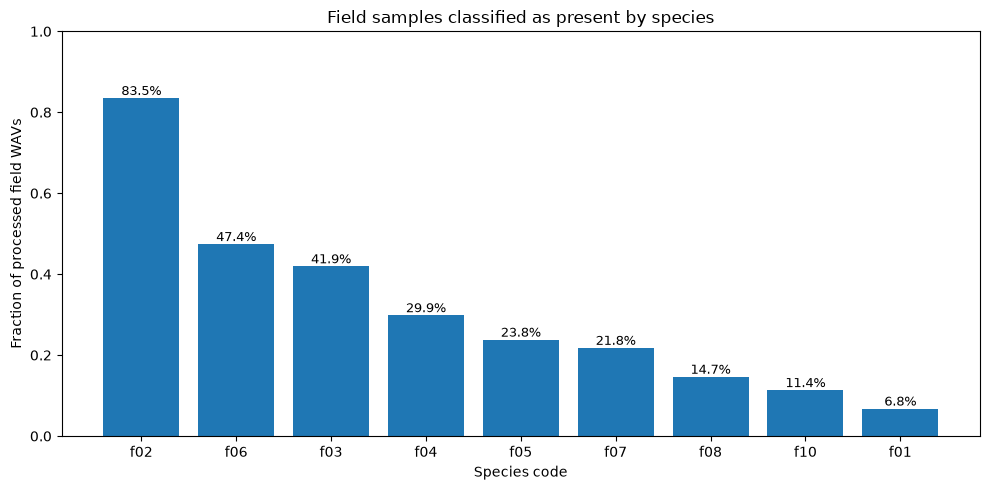

In [6]:
plot_presence = (
    presence_summary[
        presence_summary["modelled"]
    ]
    .sort_values(
        "presence_fraction",
        ascending=False,
    )
)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.bar(
    plot_presence["code"],
    plot_presence["presence_fraction"],
)

ax.set(
    title="Field samples classified as present by species",
    xlabel="Species code",
    ylabel="Fraction of processed field WAVs",
    ylim=(0, 1),
)

for index, row in enumerate(
    plot_presence.itertuples(
        index=False
    )
):
    ax.text(
        index,
        row.presence_fraction,
        f"{row.presence_fraction:.1%}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

## 6. Raw detector decisions and accepted calls

This section separates:

- all candidate intervals sent to the detector;
- accepted candidate decisions;
- accepted detections after temporal deduplication.

A high number of accepted segments is not equivalent to abundance. Multiple candidates can arise from
one vocal event, repeated calls from the same individual, or overlapping segmentation bands.

In [7]:
if "accepted" not in field_detections.columns:
    raise KeyError(
        "field_detector_decisions.csv does not contain 'accepted'."
    )

accepted_raw = (
    field_detections[
        field_detections["accepted"].astype(bool)
    ]
    .copy()
)

raw_acceptance_fraction = (
    len(accepted_raw)
    / len(field_detections)
    if len(field_detections)
    else np.nan
)

print("All detector decisions :", len(field_detections))
print("Accepted raw decisions :", len(accepted_raw))
print(
    "Raw acceptance fraction:",
    round(
        raw_acceptance_fraction,
        4,
    ),
)

All detector decisions : 1376119
Accepted raw decisions : 816077
Raw acceptance fraction: 0.593


In [8]:
accepted_by_species = (
    accepted_raw.groupby(
        "prediction",
        dropna=False,
    )
    .agg(
        accepted_raw=(
            "prediction",
            "size",
        ),
        samples_with_detection=(
            "sample_id",
            "nunique",
        ),
        median_llr=(
            "llr",
            "median",
        ),
        median_duration_seconds=(
            "duration_seconds",
            "median",
        ),
    )
    .reset_index()
    .rename(
        columns={
            "prediction": "code",
        }
    )
)

accepted_by_species[
    "species"
] = accepted_by_species[
    "code"
].map(
    SPECIES
)

accepted_by_species[
    "fraction_of_all_accepted"
] = (
    accepted_by_species[
        "accepted_raw"
    ]
    / accepted_by_species[
        "accepted_raw"
    ].sum()
)

accepted_by_species = (
    accepted_by_species[
        [
            "code",
            "species",
            "accepted_raw",
            "fraction_of_all_accepted",
            "samples_with_detection",
            "median_llr",
            "median_duration_seconds",
        ]
    ]
    .sort_values(
        "accepted_raw",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    accepted_by_species.round(4)
)

accepted_by_species.to_csv(
    FIELD_DIR / "analysis_accepted_by_species.csv",
    index=False,
)

,code,species,accepted_raw,fraction_of_all_accepted,samples_with_detection,median_llr,median_duration_seconds
0,f02,Dendropsophus bifurcus,577629,0.7078,456,7.1449,0.16
1,f03,Boana cinerascens,194125,0.2379,229,10.0592,0.12
2,f06,Osteocephalus fuscifacies,23416,0.0287,259,6.2043,0.12
3,f04,Pristimantis conspicillatus,7218,0.0088,163,5.6999,0.07
4,f05,Leptodactylus discodactylus,6180,0.0076,130,7.5200,0.24
5,f07,Boana lanciformis,2858,0.0035,119,7.4369,0.13
6,f01,Boana alfaroi,2425,0.0030,37,11.2378,0.11
7,f10,Engystomops petersi,1192,0.0015,62,9.9944,0.17
8,f08,Rhinella margaritifera,1034,0.0013,80,9.0622,0.10


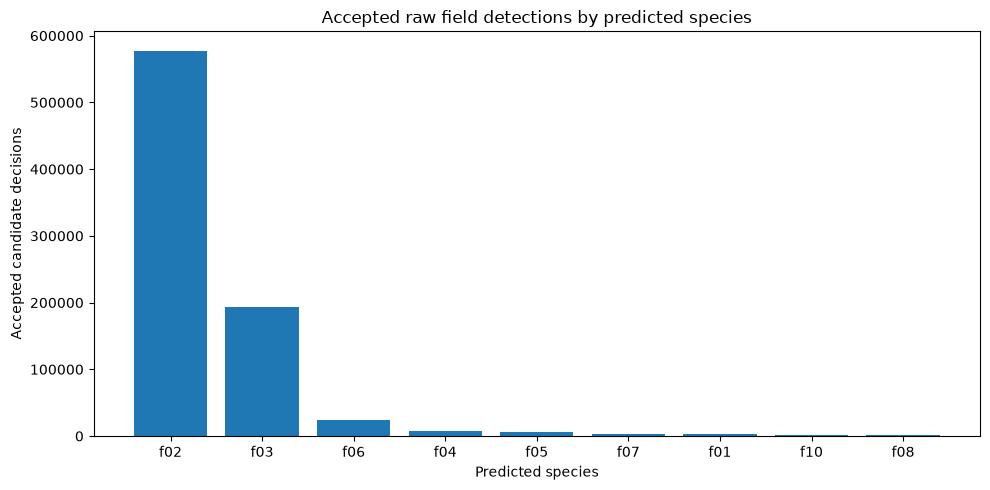

In [9]:
fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.bar(
    accepted_by_species["code"],
    accepted_by_species["accepted_raw"],
)

ax.set(
    title="Accepted raw field detections by predicted species",
    xlabel="Predicted species",
    ylabel="Accepted candidate decisions",
)

plt.tight_layout()
plt.show()

## 7. Which classes dominate the output?

This is a diagnostic, not an automatic error declaration.

A species can dominate because:

- it is genuinely common in the field recordings;
- its calls are highly repetitive;
- its acoustic model occupies a broad region of feature space;
- other environmental sounds map to that model;
- its verification threshold is comparatively permissive;
- segmentation produces many candidates likely to be assigned to that class.

Without complete manual labels, those possibilities cannot be separated conclusively.

In [10]:
dominance = accepted_by_species.copy()

dominance[
    "cumulative_fraction"
] = dominance[
    "fraction_of_all_accepted"
].cumsum()

display(
    dominance[
        [
            "code",
            "species",
            "accepted_raw",
            "fraction_of_all_accepted",
            "cumulative_fraction",
        ]
    ].round(4)
)

,code,species,accepted_raw,fraction_of_all_accepted,cumulative_fraction
0,f02,Dendropsophus bifurcus,577629,0.7078,0.7078
1,f03,Boana cinerascens,194125,0.2379,0.9457
2,f06,Osteocephalus fuscifacies,23416,0.0287,0.9744
3,f04,Pristimantis conspicillatus,7218,0.0088,0.9832
4,f05,Leptodactylus discodactylus,6180,0.0076,0.9908
5,f07,Boana lanciformis,2858,0.0035,0.9943
6,f01,Boana alfaroi,2425,0.0030,0.9973
7,f10,Engystomops petersi,1192,0.0015,0.9987
8,f08,Rhinella margaritifera,1034,0.0013,1.0000


## 8. Segmentation band versus final prediction

The frontend runs independently for each species frequency band, while classification evaluates all GMMs.
Therefore the species whose band proposed a candidate does not necessarily equal the final hypothesis.

This matrix helps diagnose whether certain bands generate disproportionately many accepted candidates.

In [11]:
band_prediction = pd.crosstab(
    accepted_raw[
        "segmentation_code"
    ],
    accepted_raw[
        "prediction"
    ],
)

display(
    band_prediction
)

band_prediction.to_csv(
    FIELD_DIR / "analysis_band_vs_prediction.csv"
)

prediction,f01,f02,f03,f04,f05,f06,f07,f08,f10
segmentation_code,,,,,,,,,
f01,222,78018,22784,995,733,3900,334,177,69
f02,665,73195,19464,408,89,3608,27,106,30
f03,124,39278,19165,1256,234,1252,281,69,192
f04,21,62025,10099,845,2407,3118,190,36,34
f05,629,77036,21893,540,225,3749,305,167,44
f06,113,66731,21926,1031,1075,1830,290,59,108
f07,159,77052,23791,1020,931,2306,530,80,321
f08,323,24922,30184,291,34,234,311,180,113
f10,169,79372,24819,832,452,3419,590,160,281


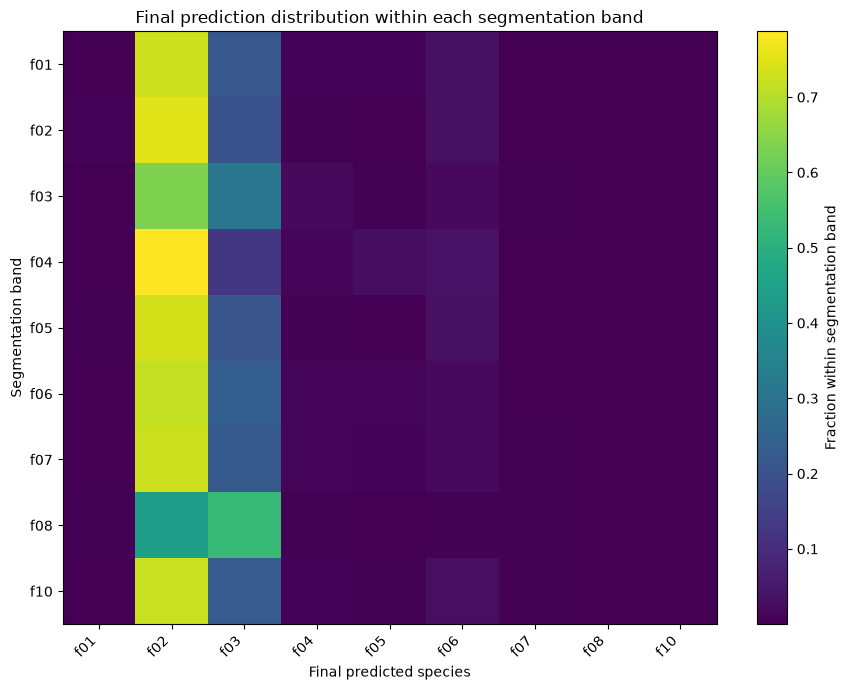

In [12]:
band_prediction_fraction = (
    band_prediction.div(
        band_prediction.sum(
            axis=1
        ).replace(
            0,
            np.nan,
        ),
        axis=0,
    )
)

fig, ax = plt.subplots(
    figsize=(9, 7)
)

image = ax.imshow(
    band_prediction_fraction.to_numpy(),
    aspect="auto",
)

ax.set_xticks(
    np.arange(
        len(
            band_prediction_fraction.columns
        )
    )
)

ax.set_xticklabels(
    band_prediction_fraction.columns,
    rotation=45,
    ha="right",
)

ax.set_yticks(
    np.arange(
        len(
            band_prediction_fraction.index
        )
    )
)

ax.set_yticklabels(
    band_prediction_fraction.index
)

ax.set(
    title="Final prediction distribution within each segmentation band",
    xlabel="Final predicted species",
    ylabel="Segmentation band",
)

fig.colorbar(
    image,
    ax=ax,
    label="Fraction within segmentation band",
)

plt.tight_layout()
plt.show()

## 9. Field LLR behavior

Notebook 07 calibrated the detector using labelled Dataset-1 calls. Field audio is a different acoustic
domain, containing unmodelled species, insects and environmental noise.

Comparing LLR distributions across predicted classes helps identify unusual field behavior, but it must
not be used here to retune thresholds after seeing the test corpus.

In [13]:
llr_summary = (
    field_detections[
        field_detections[
            "feature_valid"
        ].astype(bool)
    ]
    .groupby(
        "hypothesis"
    )
    .agg(
        n_candidates=(
            "llr",
            "size",
        ),
        median_llr=(
            "llr",
            "median",
        ),
        q10_llr=(
            "llr",
            lambda x:
                x.quantile(0.10),
        ),
        q90_llr=(
            "llr",
            lambda x:
                x.quantile(0.90),
        ),
        acceptance_fraction=(
            "accepted",
            "mean",
        ),
    )
    .reset_index()
    .rename(
        columns={
            "hypothesis": "code",
        }
    )
)

llr_summary[
    "species"
] = llr_summary[
    "code"
].map(
    SPECIES
)

display(
    llr_summary[
        [
            "code",
            "species",
            "n_candidates",
            "median_llr",
            "q10_llr",
            "q90_llr",
            "acceptance_fraction",
        ]
    ].round(4)
)

llr_summary.to_csv(
    FIELD_DIR / "analysis_field_llr_summary.csv",
    index=False,
)

,code,species,n_candidates,median_llr,q10_llr,q90_llr,acceptance_fraction
0,f01,Boana alfaroi,3550,9.8860,3.8942,14.4285,0.6831
1,f02,Dendropsophus bifurcus,638803,6.7390,3.7459,11.7176,0.9042
2,f03,Boana cinerascens,455382,6.3673,3.5352,12.7365,0.4263
3,f04,Pristimantis conspicillatus,68115,3.6511,2.5435,5.1153,0.1060
4,f05,Leptodactylus discodactylus,11718,5.7600,2.9033,10.1274,0.5274
5,f06,Osteocephalus fuscifacies,138316,3.7970,2.4188,5.9747,0.1693
6,f07,Boana lanciformis,14359,3.5132,1.9258,7.4035,0.1990
7,f08,Rhinella margaritifera,3587,5.2489,2.3778,9.9614,0.2883
8,f10,Engystomops petersi,42289,3.8883,2.3029,6.5196,0.0282


## 10. Results by pond

The available paths may not always encode pond metadata perfectly. Rows labelled `unknown` are retained
instead of being silently reassigned.

In [14]:
presence_columns = [
    f"presence_{code_name}"
    for code_name in MODELLED_CODES
]

if "pond" in field_presence.columns:
    pond_presence = (
        field_presence.groupby(
            "pond",
            dropna=False,
        )[
            presence_columns
        ]
        .mean()
        .reset_index()
    )

    display(
        pond_presence.round(3)
    )

    pond_presence.to_csv(
        FIELD_DIR / "analysis_presence_by_pond.csv",
        index=False,
    )
else:
    pond_presence = pd.DataFrame()
    print("No pond column available.")

,pond,presence_f01,presence_f02,presence_f03,presence_f04,presence_f05,presence_f06,presence_f07,presence_f08,presence_f10
0,P1,0.000,1.000,1.000,0.286,0.429,1.000,0.714,0.000,0.143
1,P2,0.000,1.000,0.667,0.667,0.333,1.000,0.667,0.000,1.000
2,unknown,0.069,0.832,0.410,0.297,0.235,0.465,0.209,0.149,0.108


## 11. Results by month

In [15]:
if "month" in field_presence.columns:
    month_presence = (
        field_presence.groupby(
            "month",
            dropna=False,
        )[
            presence_columns
        ]
        .mean()
        .reset_index()
    )

    display(
        month_presence.round(3)
    )

    month_presence.to_csv(
        FIELD_DIR / "analysis_presence_by_month.csv",
        index=False,
    )
else:
    month_presence = pd.DataFrame()
    print("No month column available.")

,month,presence_f01,presence_f02,presence_f03,presence_f04,presence_f05,presence_f06,presence_f07,presence_f08,presence_f10
0,unknown,0.068,0.835,0.419,0.299,0.238,0.474,0.218,0.147,0.114


## 12. How many species are marked present per field WAV?

This is a useful sanity check for the resulting presence vectors.

In [16]:
field_presence[
    "modelled_species_present"
] = (
    field_presence[
        presence_columns
    ]
    .apply(
        pd.to_numeric,
        errors="coerce",
    )
    .sum(
        axis=1
    )
)

species_per_sample_summary = (
    field_presence[
        "modelled_species_present"
    ]
    .describe()
)

display(
    species_per_sample_summary.to_frame(
        "value"
    ).round(4)
)

,value
count,546.0000
mean,2.8114
std,2.2198
min,0.0000
25%,1.0000
50%,2.0000
75%,5.0000
max,9.0000


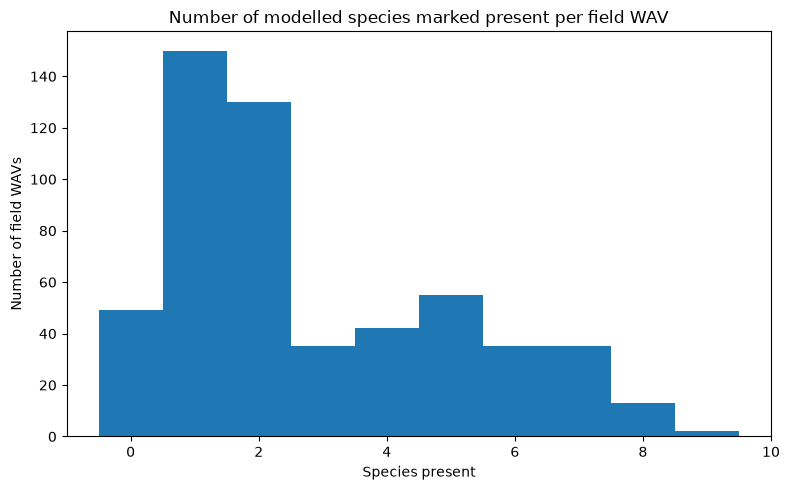

In [17]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

values = (
    field_presence[
        "modelled_species_present"
    ]
    .dropna()
    .astype(int)
)

bins = np.arange(
    values.min() - 0.5,
    values.max() + 1.5,
    1,
)

ax.hist(
    values,
    bins=bins,
)

ax.set(
    title="Number of modelled species marked present per field WAV",
    xlabel="Species present",
    ylabel="Number of field WAVs",
)

plt.tight_layout()
plt.show()

## 13. Methodological comparison with the paper

This table separates what was reproduced conceptually from what differs because of the recovered data or
because our experiments selected a different configuration.

In [18]:
method_comparison = pd.DataFrame([
    {
        "stage": "Field input",
        "paper": "141 nominal 10-minute field samples; 23.5 h",
        "replication": (
            f"{len(field_presence)} processed recovered field WAVs"
        ),
        "status": "Same methodological role; different available data",
    },
    {
        "stage": "Field blocking",
        "paper": "30-second blocks",
        "replication": "30-second blocks",
        "status": "Reproduced",
    },
    {
        "stage": "Endpoint segmentation",
        "paper": "species band + STE 10 ms + MA=12 + 3/3 rule",
        "replication": "same conceptual frontend",
        "status": "Reproduced conceptually",
    },
    {
        "stage": "Endpoint threshold constant C",
        "paper": "empirical C, value not reported",
        "replication": "species-specific C selected on Dataset 1",
        "status": "Replication decision required",
    },
    {
        "stage": "Features",
        "paper": "20 modified cepstral coefficients (m-FCC final system)",
        "replication": "20 PLP-RASTA",
        "status": "Documented empirical divergence",
    },
    {
        "stage": "GMM order",
        "paper": "M=64 final system",
        "replication": "M=4",
        "status": "Documented robust-selection divergence",
    },
    {
        "stage": "Species models",
        "paper": "10",
        "replication": f"{len(MODELLED_CODES)}; f09 unavailable",
        "status": "Recovered-data limitation",
    },
    {
        "stage": "Verification",
        "paper": "winner GMM + median-alternative LLR + class threshold",
        "replication": "same conceptual rule",
        "status": "Reproduced",
    },
    {
        "stage": "Presence rule",
        "paper": "one accepted call is enough for presence",
        "replication": "one accepted call is enough for presence",
        "status": "Reproduced",
    },
    {
        "stage": "Independent field metrics",
        "paper": "18 manually labelled samples",
        "replication": "not computed without complete recovered ground truth",
        "status": "Not directly reproducible from available labels",
    },
])

display(
    method_comparison
)

method_comparison.to_csv(
    FIELD_DIR / "analysis_methodological_comparison.csv",
    index=False,
)

,stage,paper,replication,status
0,Field input,141 nominal 10-minute field samples; 23.5 h,546 processed recovered field WAVs,Same methodological role; different available ...
1,Field blocking,30-second blocks,30-second blocks,Reproduced
2,Endpoint segmentation,species band + STE 10 ms + MA=12 + 3/3 rule,same conceptual frontend,Reproduced conceptually
3,Endpoint threshold constant C,"empirical C, value not reported",species-specific C selected on Dataset 1,Replication decision required
4,Features,20 modified cepstral coefficients (m-FCC final...,20 PLP-RASTA,Documented empirical divergence
5,GMM order,M=64 final system,M=4,Documented robust-selection divergence
6,Species models,10,9; f09 unavailable,Recovered-data limitation
7,Verification,winner GMM + median-alternative LLR + class th...,same conceptual rule,Reproduced
8,Presence rule,one accepted call is enough for presence,one accepted call is enough for presence,Reproduced
9,Independent field metrics,18 manually labelled samples,not computed without complete recovered ground...,Not directly reproducible from available labels


## 14. Paper metrics for reference only

The article reports on its manually labelled 18-sample subset:

- Recall = 0.875
- Precision = 1.000
- F1 = 0.933
- MCC = 0.914
- Specificity = 1.000
- Accuracy ≈ 0.966

These values belong to the **paper's field evaluation**. They must not be presented as our metrics.

Our field corpus does not currently provide an equivalent complete manually labelled test matrix, so
there is no valid direct numerical accuracy comparison.

In [19]:
paper_metrics = pd.DataFrame([
    ("Recall", 0.875),
    ("Precision", 1.000),
    ("F1", 0.933),
    ("MCC", 0.914),
    ("Specificity", 1.000),
    ("Accuracy", 0.966),
], columns=[
    "metric",
    "paper_reported_value",
])

display(
    paper_metrics
)

,metric,paper_reported_value
0,Recall,0.875
1,Precision,1.000
2,F1,0.933
3,MCC,0.914
4,Specificity,1.000
5,Accuracy,0.966


## 15. Automatic diagnostic flags

These flags are intentionally descriptive. They identify things worth discussing, not automatic reasons
to modify the frozen model.

In [20]:
diagnostic_rows = []

if len(accepted_by_species):
    top = accepted_by_species.iloc[0]

    diagnostic_rows.append({
        "diagnostic": "dominant_accepted_class",
        "value": top["code"],
        "detail": (
            f"{top['fraction_of_all_accepted']:.1%} "
            "of accepted raw detections"
        ),
    })

for row in accepted_by_species.itertuples(
    index=False
):
    if row.fraction_of_all_accepted >= 0.50:
        diagnostic_rows.append({
            "diagnostic": "class_over_half_of_raw_accepts",
            "value": row.code,
            "detail": (
                f"{row.fraction_of_all_accepted:.1%}"
            ),
        })

for row in presence_summary[
    presence_summary["modelled"]
].itertuples(
    index=False
):
    if row.presence_fraction >= 0.80:
        diagnostic_rows.append({
            "diagnostic": "very_high_presence_fraction",
            "value": row.code,
            "detail": (
                f"{row.presence_fraction:.1%} of field WAVs"
            ),
        })

diagnostics = pd.DataFrame(
    diagnostic_rows
)

display(
    diagnostics
)

diagnostics.to_csv(
    FIELD_DIR / "analysis_diagnostic_flags.csv",
    index=False,
)

,diagnostic,value,detail
0,dominant_accepted_class,f02,70.8% of accepted raw detections
1,class_over_half_of_raw_accepts,f02,70.8%
2,very_high_presence_fraction,f02,83.5% of field WAVs


## 16. Final interpretation template

After execution, the findings should be reported in four separate layers.

### A. What was reproduced

The complete methodological chain of the article was implemented:

**labelled calls → feature extraction → species GMMs → LLR verification → automatic segmentation →
field presence/absence.**

### B. What differs from the article

Differences in:

- number and duration of recovered field WAVs;
- unavailable `f09` model;
- final PLP-RASTA feature choice;
- final GMM order;
- reconstructed segmentation parameters;

must be documented, but they do not invalidate a **methodological replication**.

### C. What the field output shows

Use:

- `presence_summary`;
- `accepted_by_species`;
- `band_prediction`;
- `llr_summary`;
- pond/month summaries.

These are observations from our detector on the recovered field corpus.

### D. What cannot be claimed

Without complete independent manual presence/absence labels, do **not** claim field accuracy, precision,
recall, specificity or F1 for our 546-file run.

Detector output and biological truth are not interchangeable just because both fit conveniently in a
CSV.

## 17. Save a compact analysis manifest

In [21]:
analysis_manifest = {
    "source_notebook": "10_field_results_analysis",
    "input_notebook": "09_field_presence_absence",
    "analysis_only": True,
    "models_changed": False,
    "thresholds_changed": False,
    "segmentation_changed": False,
    "field_samples_analyzed": int(
        len(field_presence)
    ),
    "modelled_species": list(
        MODELLED_CODES
    ),
    "unmodelled_species": [
        code_name
        for code_name in PAPER_ORDER
        if code_name not in MODELLED_CODES
    ],
    "direct_field_accuracy_comparison_to_paper": False,
    "reason": (
        "complete independent manually labelled field presence/absence "
        "ground truth is not available for the recovered field corpus"
    ),
}

with open(
    FIELD_DIR / "analysis_manifest.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        analysis_manifest,
        f,
        indent=2,
    )

print(
    json.dumps(
        analysis_manifest,
        indent=2,
    )
)

{
  "source_notebook": "10_field_results_analysis",
  "input_notebook": "09_field_presence_absence",
  "analysis_only": true,
  "models_changed": false,
  "thresholds_changed": false,
  "segmentation_changed": false,
  "field_samples_analyzed": 546,
  "modelled_species": [
    "f01",
    "f02",
    "f03",
    "f04",
    "f05",
    "f06",
    "f07",
    "f08",
    "f10"
  ],
  "unmodelled_species": [
    "f09"
  ],
  "direct_field_accuracy_comparison_to_paper": false,
  "reason": "complete independent manually labelled field presence/absence ground truth is not available for the recovered field corpus"
}
